In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import sph_harm_y

In [3]:
#parameters

np.random.seed(7)

#mean CMB temperature in Kelvin
T0 = 2.7255
#rms fluctuations in microkelvin
RMS_uK = 100
#max multiple moment
lmax = 35

n_theta = 181
n_phi = 360

In [4]:
#spherical coords

theta = np.linspace(0.001, np.pi - 0.001, n_theta)
phi = np.linspace(-np.pi, np.pi, endpoint=False)

PHI, THETA = np.meshgrid(phi, theta)

In [8]:
#cmb temperature field

cmb = np.zeros(THETA.shape, dtype=complex)

for l in range(2,lmax+1):
    Cl = 1 / (l * (l + 1)) * np.exp(-(l / 55)**2)
    # m = 0 mode
    a_l0 = np.random.normal() * np.sqrt(Cl)

    cmb += a_l0 * sph_harm_y(l, 0, THETA, phi)

    #positive and negative m modes

    for m in range(1, l + 1):
        a_lm = np.sqrt(Cl / 2) * (np.random.normal() + 1j * np.random.normal())
        Y_pos = sph_harm_y(l, m, THETA, PHI)
        Y_neg = sph_harm_y(l, -m, THETA, PHI)

        cmb += a_lm * Y_pos + (-1)**m * np.conjugate(a_lm) * Y_neg

In [10]:
#temperature fluctuations

delta_T = np.real(cmb)

#remove mean
delta_T -= np.mean(delta_T)

#normalize rms
delta_T_uK = delta_T / np.std(delta_T) * RMS_uK

#convert microkelvin to kelvin
delta_T_K = delta_T_uK * 1e-6

#actual temperature field
temperature = T0 + delta_T_K

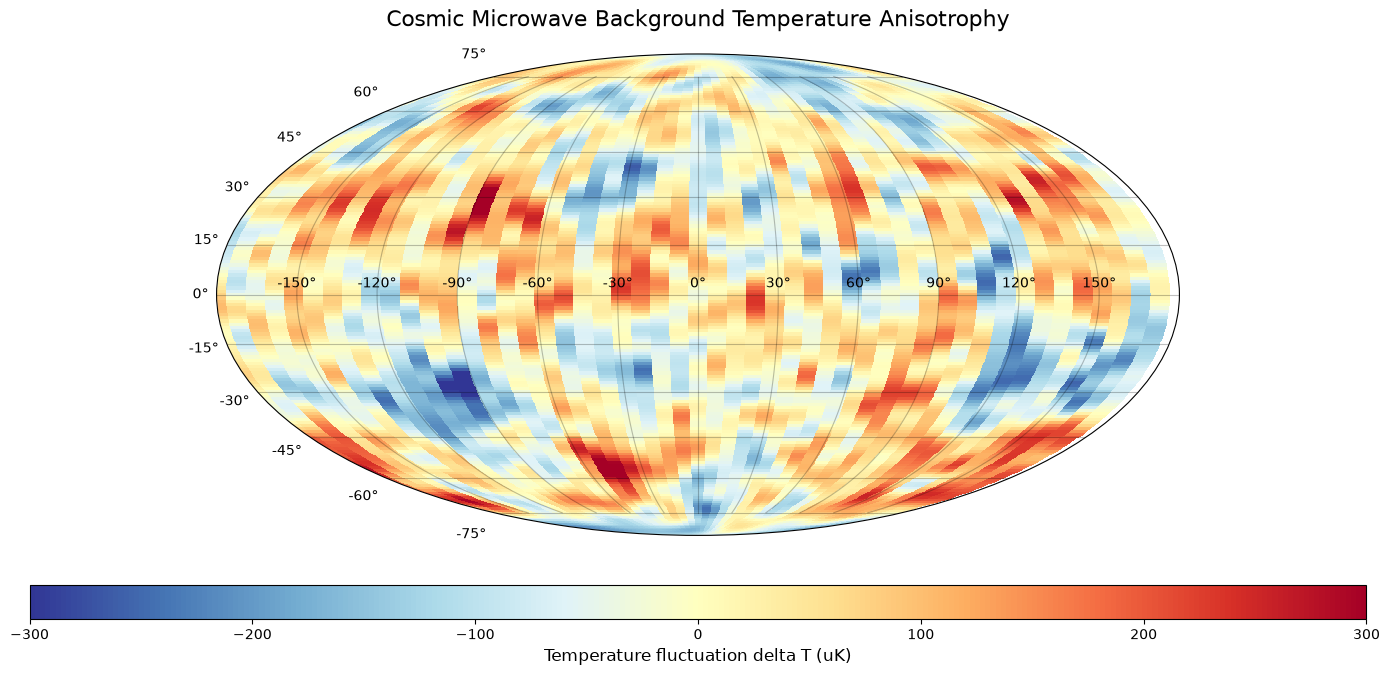

In [11]:
#display cmb map

fig = plt.figure(figsize=(14,7))


ax = fig.add_subplot(111, projection="mollweide")

im = ax.pcolormesh(PHI, np.pi / 2 - THETA, delta_T_uK, cmap="RdYlBu_r", shading="auto", vmin=-300, vmax=300)

ax.grid(color="black", alpha=0.25)

ax.set_title("Cosmic Microwave Background Temperature Anisotrophy", fontsize=16, pad=20)

cbar =  plt.colorbar(im, orientation="horizontal", pad=0.08, aspect=40)

cbar.set_label("Temperature fluctuation delta T (uK)", fontsize=12)

plt.tight_layout()
plt.show()

In [12]:
#results

print("CMB SIMULATION RESULTS")

print("Mean CMB Temperature:", T0, "K")
print("Mean fluctuation:", np.mean(delta_T_uK), "uK")
print("RMS fluctuation:", np.std(delta_T_uK), "uK")
print("Maximum multipole:", lmax)

CMB SIMULATION RESULTS
Mean CMB Temperature: 2.7255 K
Mean fluctuation: -2.411919651110528e-15 uK
RMS fluctuation: 100.0 uK
Maximum multipole: 35
